# California Housing Price Prediction

This notebook presents a comprehensive data science project for analyzing and predicting real estate prices in California using Scikit-Learn's **Linear Regression** algorithm. The dataset is loaded directly from Google Colab's default environment sample data (`california_housing.csv`).

## Table of Contents
* Import Libraries & Setup
* Define Preprocessing & Split Pipelines
* Define Evaluation Metrics & Plotting Utilities
* Load Dataset & Exploratory Data Analysis
* Handle Missing Values
* Train Baseline Model (V1)
* Feature Engineering & Optimized Model (V2)

## Import Libraries & Setup
In this initial section, we import all essential libraries for data manipulation, numerical analysis, data visualization, structured preprocessing, and modeling.

In [ ]:
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

poly_reg = PolynomialFeatures(degree=2)
lin_reg = LinearRegression()

## Data Preprocessing & Split Pipelines
We define a modular pipeline function using `ColumnTransformer` to automate numeric feature scaling with `StandardScaler` and apply `OneHotEncoder` to encode the categorical column `ocean_proximity` seamlessly.

In [ ]:
def train_test_features(dataset):
  X = dataset.drop(columns='median_house_value')
  y = dataset['median_house_value']

  # Identifica automaticamente colunas numéricas e categóricas pelos nomes
  num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
  cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

  # Configura o transformer utilizando os nomes das colunas ao invés de fatiamentos por índice
  transformer = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ],
    remainder='passthrough'
  )

  X_train = transformer.fit_transform(X_train)
  X_test = transformer.transform(X_test)

  return X_train, X_test, y_train, y_test

## Define Evaluation Metrics & Plotting Utilities
We build an evaluation utility function to plot the actual vs. predicted target values, visualize residual errors, and compute standard regression metrics (MAE, MSE, RMSE, and $R^2$ score).

In [ ]:
def show_grafic_metrics(y_test, y_pred):
  # Configurando o estilo dos gráficos
  sns.set_theme(style="whitegrid")
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

  # 1. Gráfico de Dispersão: Valores Reais vs. Preditos
  ax1.scatter(y_test, y_pred, color='blue', alpha=0.7, edgecolors='k', s=80)
  # Linha de referência (Predição Perfeita)
  lims = [min(min(y_test), min(y_pred)), max(max(y_test), max(y_pred))]
  ax1.plot(lims, lims, color='red', linestyle='--', lw=2, label='Predição Perfeita')
  ax1.set_xlabel('Valores Reais', fontsize=12)
  ax1.set_ylabel('Valores Preditos)', fontsize=12)
  ax1.set_title('Valores Reais vs. Valores Preditos', fontsize=14)
  ax1.legend()

  # 2. Gráfico de Resíduos (Erros)
  residuals = y_test - y_pred
  ax2.scatter(y_pred, residuals, color='purple', alpha=0.7, edgecolors='k', s=80)
  ax2.axhline(y=0, color='red', linestyle='--', lw=2)
  ax2.set_xlabel('Valores Preditos', fontsize=12)
  ax2.set_ylabel('Resíduos (Erros)', fontsize=12)
  ax2.set_title('Gráfico de Resíduos (Análise de Erro)', fontsize=14)

  plt.tight_layout()
  plt.show()

  print('\n RESULTADOS TREINAMENTO')
  print(f'MAE (Erro Médio Absoluto): {mean_absolute_error(y_test, y_pred)}')
  print(f'MSE (Erro Quadrático Médio): {mean_squared_error(y_test, y_pred)}')
  print(f'RMSE (Raiz do Erro Quadrático): {root_mean_squared_error(y_test, y_pred)}')
  print(f'R2_SCORE (Coeficiente R²): {r2_score(y_test, y_pred)}')


## Load Dataset & Exploratory Data Analysis (EDA)
We load the California housing dataset and perform an initial check to inspect its structure and identify the presence of null values across the columns.

In [ ]:
dataset = pd.read_csv('/datasets/california_housing.csv')
dataset.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

## Handle Missing Values
We handle any missing values in the dataset using a structured `SimpleImputer` configured with the `mean` strategy to ensure robust data alignment without distorting feature distributions.

In [ ]:
imp_mean = SimpleImputer(missing_values=np.nan, strategy='mean')
imp_mean.fit(dataset.iloc[:, [4]])
dataset.iloc[:, [4]] = imp_mean.transform(dataset.iloc[:, [4]])
dataset.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

## Train Baseline Model (V1)
We split our cleaned dataset into training and testing sets, fit the baseline Linear Regression model, and evaluate its raw predictive performance.

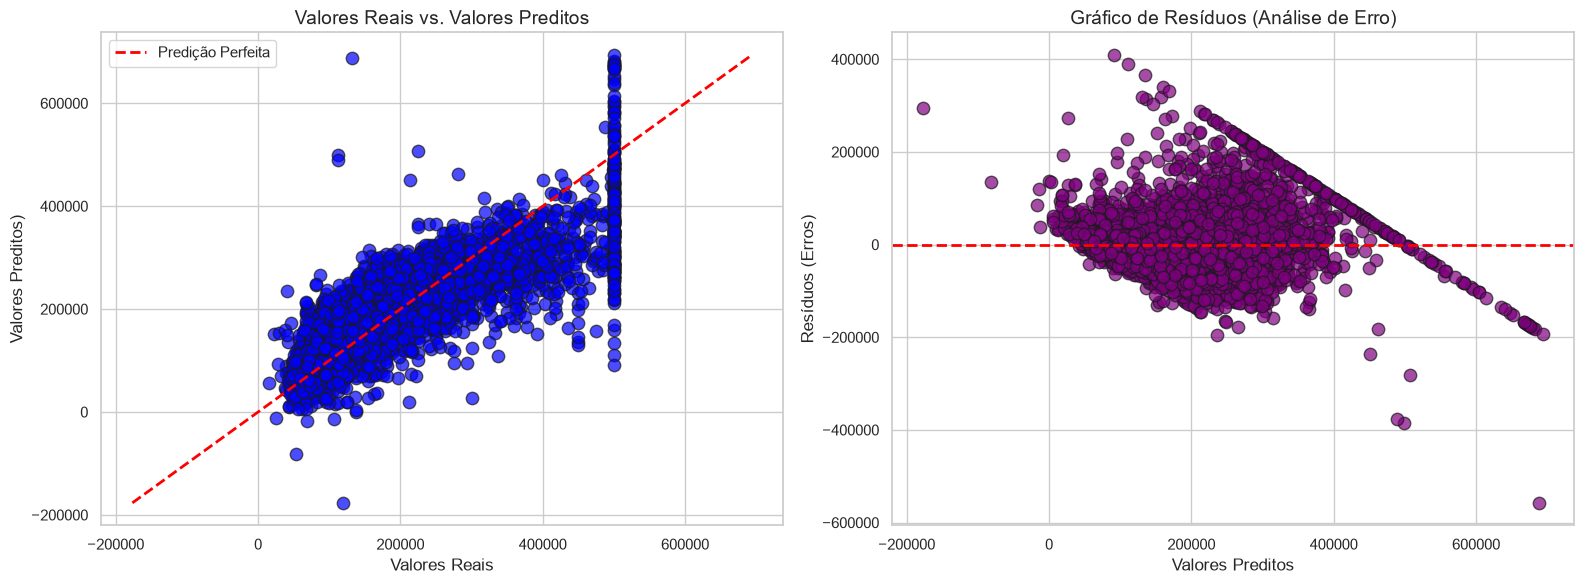


 RESULTADOS TREINAMENTO
MAE (Erro Médio Absoluto): 49766.766287447026
MSE (Erro Quadrático Médio): 4754050720.172423
RMSE (Raiz do Erro Quadrático): 68949.6245107428
R2_SCORE (Coeficiente R²): 0.6375631694383718


In [ ]:
# Ajuste para a nova assinatura sem passar a posição por parâmetro
X_train_v1, X_test_v1, y_train_v1, y_test_v1 = train_test_features(dataset)

X_poly_v1 = poly_reg.fit_transform(X_train_v1)

lin_reg.fit(X_poly_v1, y_train_v1)

# Transformar os dados de teste utilizando o polinômio de grau 2 criado anteriormente
X_test_poly = poly_reg.transform(X_test_v1)

# Realizar as predições no conjunto de teste
y_pred_v1 = lin_reg.predict(X_test_poly)

# Exibir os gráficos e as métricas de avaliação
show_grafic_metrics(y_test_v1, y_pred_v1)

## Feature Engineering & Optimized Model (V2)
To enhance performance, we perform feature engineering to extract meaningful ratios (e.g., rooms per household, population per household) and handle price cap outliers (truncating records with target value >= 500k) before re-training.

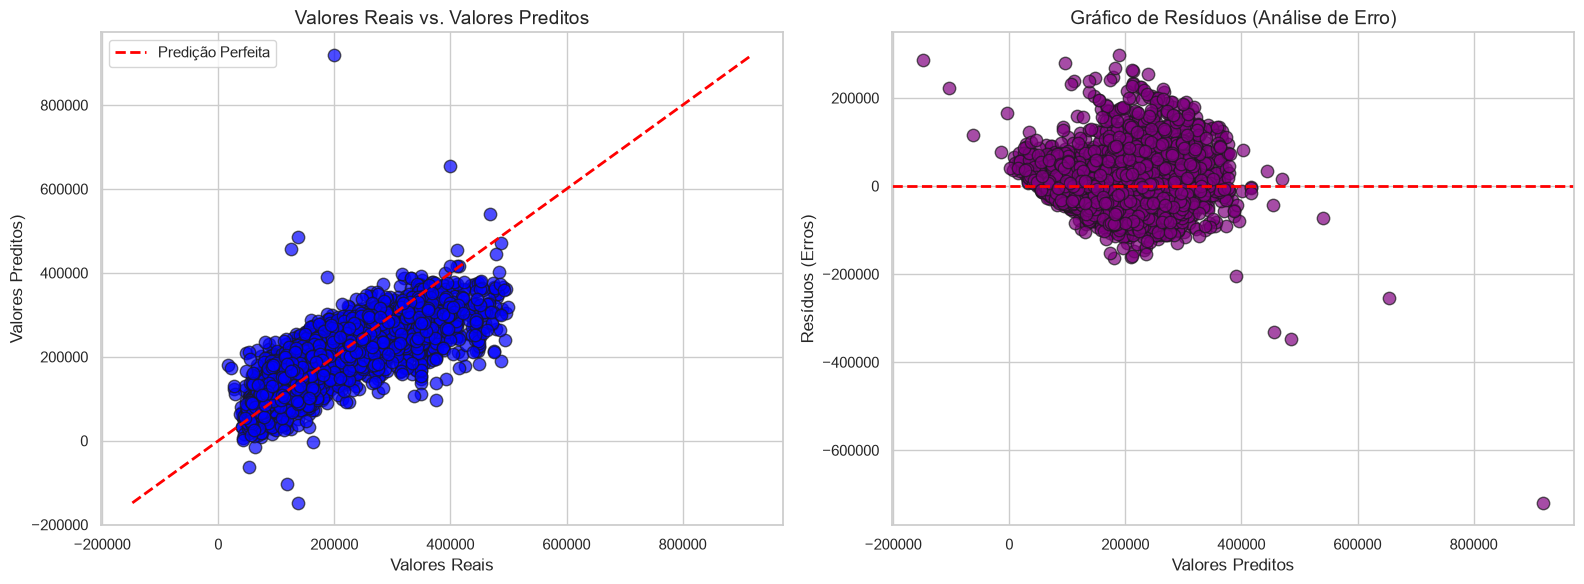


 RESULTADOS TREINAMENTO
MAE (Erro Médio Absoluto): 43918.15910597992
MSE (Erro Quadrático Médio): 3626812641.532566
RMSE (Raiz do Erro Quadrático): 60223.02418122629
R2_SCORE (Coeficiente R²): 0.6168516171352518


In [ ]:
dataset_v2 = dataset[dataset['median_house_value'] < 500000].copy()
dataset_v2['rooms_per_household'] = dataset_v2['total_rooms']/dataset_v2['households']
dataset_v2['bedrooms_per_room'] = dataset_v2['total_bedrooms']/dataset_v2['total_rooms']
dataset_v2['population_per_household'] = dataset_v2['population']/dataset_v2['households']

# Separação robusta de treino e teste
X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_features(dataset_v2)

# Instanciando um novo transformador polinomial específico para as colunas da V2
poly_reg_v2 = PolynomialFeatures(degree=2)
X_poly_v2 = poly_reg_v2.fit_transform(X_train_v2)
X_test_poly_v2 = poly_reg_v2.transform(X_test_v2)

# Ajustando o Ridge com alpha=50.0 para maior estabilidade matemática
ridge_reg = Ridge(alpha=50.0)
ridge_reg.fit(X_poly_v2, y_train_v2)

y_pred_v2 = ridge_reg.predict(X_test_poly_v2)

show_grafic_metrics(y_test_v2, y_pred_v2)